In [1]:
import glob
import numpy as np
import os
import matplotlib.pyplot as plt 
import torch
from models.functions import * 
from models.definitions import ContextualUNet1D
from helpers.zero_handlers import *
import pandas as pd
import pywt
import antropy as ant
from scipy import stats

pd.set_option('display.max_columns', 30)

In [2]:
# Methods that are going are used inside `process_all_data` function

ZERO_HANDLERS = {
    "drop_zeros": drop_zeros,
    "interpolate": interpolate_zeros,
    "drop_long_then_interpolate": lambda s: interpolate_zeros(drop_long_zero_regions(s, cutoff=10)),
    "drop_long_then_weighted_fill":  lambda s: weighted_average_zipper(drop_long_zero_regions(s, cutoff=10)),
}

def process_all_data(
    all_data,
    method="interpolate",
    cutoff=10,
    model=None,
    stats=None,
    device="cpu",
):
    """
    Process all signals using selected zero-handling method.
    Input: stage 1 and stage 2 signal for each instance
    """
    processed_data = {}

    for dataset, ids in all_data.items():
        processed_data[dataset] = {}
        
        for signal_id, stages in ids.items():
            processed_data[dataset][signal_id] = {}
                
            for stage, signals in stages.items():
                fhr = signals["fhr"]
                uc = signals["uc"]

                # Autoencoder or hybrid methods
                if method in ["drop_long_then_autoencoder"]: # used to have more
                    if method == "autoencoder":
                        processed = autoencoder_inpaint(fhr, uc, model, stats, device)
                    else:  # drop_long_then_autoencoder
                        processed = drop_long_then_autoencoder(fhr, uc, model, stats, device, cutoff=cutoff)
                
                # Simpler zero-handling methods
                else:
                    handler = ZERO_HANDLERS[method]
                    processed = handler(fhr)

                processed_data[dataset][signal_id][stage] = processed

    return processed_data

In [3]:
def extract_fhr_features(fhr, wavelet_level=5):
    """
    Compute statistical, HRV, wavelet, and entropy features for one FHR signal.
    """
    # Time-domain 
    mean = np.mean(fhr)
    std = np.std(fhr)
    median = np.median(fhr)
    minimum = np.min(fhr)
    maximum = np.max(fhr)
    range_val = maximum - minimum
    
    diffs = np.diff(fhr)
    squared_diffs = diffs**2
    max_diff = np.sqrt(np.max(squared_diffs))

    rmssd = np.sqrt(np.mean(squared_diffs))

    # Wavelet 
    max_level = pywt.dwt_max_level(len(fhr), pywt.Wavelet('haar').dec_len)
    level = min(wavelet_level, max_level)

    coeffs = pywt.wavedec(fhr, 'haar', level=level)
    if len(coeffs) == 0:  # In case of small signals (eg stage 2 being really short)
        wavelet_stds = np.array([0])
        energies = np.array([0])
    else:
        wavelet_stds = np.array([np.std(c) for c in coeffs])
        energies = np.array([np.sum(c**2) for c in coeffs])

    p = energies / (np.sum(energies) + 1e-12)
    wavelet_entropy = -np.sum(p * np.log(p + 1e-12))

    # Entropy features
    sampen = ant.sample_entropy(fhr)
    apen = ant.app_entropy(fhr)
    penten = ant.perm_entropy(fhr, normalize=True)

    # Build feature dict 
    features = {
        "mean": mean,
        "std": std,
        "median": median,
        "min": minimum,
        "max": maximum,
        "range": range_val,
        "max_diff": max_diff,
        "rmssd": rmssd,
        "wavelet_entropy": wavelet_entropy,
        "sample_entropy": sampen,
        "approx_entropy": apen,
        "perm_entropy": penten
    }

    # Add wavelet stds as separate columns
    for i, wstd in enumerate(wavelet_stds):
        features[f"wavelet_std_L{i}"] = wstd

    return features

In [4]:
# Reading only the 15% file

DIRS = [
    # "0.05_data",
    # "0.1_data",
    "0.15_data",
    # "0.2_data"
   ]
all_data = {
    # "0.05_data": {},
    # "0.1_data": {}, 
    "0.15_data": {},
    # "0.2_data": {}
}

DS = "0.15_data"

df = pd.read_csv("data/hea.csv", index_col=0)

fhr_gain, fhr_baseline = 100.0, 0.0 # based on hea files
for DIR in DIRS:
    DATABASE_PATH = f"data/zero_quantiles/{DIR}/*.dat"
    for dat_file in glob.glob(DATABASE_PATH):
        rec_id = int(dat_file.split("/")[-1].split(".")[0])
        raw_data = np.fromfile(dat_file, dtype=np.int16)
        fhr = (raw_data[0::2] - fhr_baseline) / fhr_gain
        uc = raw_data[1::2]

        cuttoff_in_min = df[df["metadata.id"]==rec_id]["stage_2_index"]
        cuttoff = int((cuttoff_in_min * 60 * 4).iloc[0]) # 60 second/minute, 4 Hz

        all_data[DIR][rec_id] = {
            "stage_1": {"fhr": fhr[:-cuttoff], "uc": uc[:-cuttoff]}, # stage 1 is [start: end - cutoff]
            "stage_2": {"fhr": fhr[-cuttoff:], "uc": uc[-cuttoff:]}  # stage 2 is [end - cutoff: end]
        }

# Filter the dataset for the ids we are going to use
df_15 = df[df['metadata.id'].isin(all_data[DS].keys())]
df_15.drop(columns=["stage_2_index"], inplace=True, errors="pass") # only used for stage 1 and stage 2 separation

/tmp/ipykernel_9612/3418666631.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_15.drop(columns=["stage_2_index"], inplace=True, errors="pass") # only used for stage 1 and stage 2 separation


### <u>Testing all zero-handling methods</u>

In [ ]:
# Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the autoencoder model and stats once
model, model_stats = load_best_ae_and_stats("results/autoencoder/grid_search/best_inpainting_model.pth", device)

# List of all available zero-handling methods
zero_methods = [
    "drop_zeros",
    "interpolate",
    "drop_long_then_interpolate",
    "drop_long_then_weighted_fill", # Till here is the same as ZERO_HANDLERS
    "drop_long_then_autoencoder" # extra method with different handling in the `process_all_data` function
]

# Container for all results
all_processed_datasets = {}

# Loop through each method
for method in zero_methods:

    # Process with current method
    processed = process_all_data(
        all_data,
        method=method,
        cutoff=10,
        model=model,
        stats=model_stats,
        device=device,
    )
    
    # Store processed dataset
    all_processed_datasets[method] = processed

Loading model from results/autoencoder/grid_search/best_inpainting_model.pth...
Model loaded successfully.
Stats: FHR μ=137.47, σ=17.29 | UC μ=2195.35, σ=2203.97


In [6]:
# visualizing one sample 

method = "drop_long_then_autoencoder"
avail = list(all_processed_datasets['drop_long_then_interpolate']['0.15_data'].keys())
sample = avail[1]
selected_stage = "stage_1"

In [7]:
test_1 = all_processed_datasets[method]['0.15_data'][sample]["stage_1"]
original_1 = all_data['0.15_data'][sample]["stage_1"]['fhr']

test_2 = all_processed_datasets[method]['0.15_data'][sample]["stage_2"]
original_2 = all_data['0.15_data'][sample]["stage_2"]['fhr']

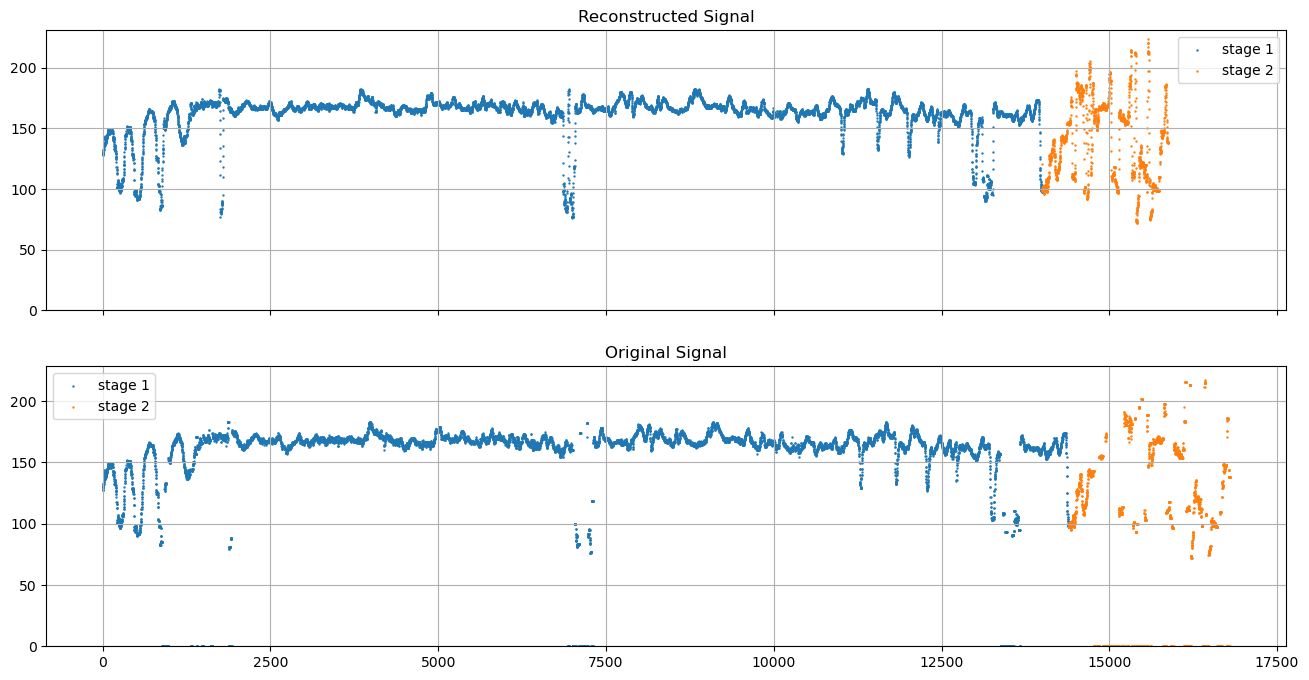

In [8]:
MARKER_SIZE = 0.5

fig, axes = plt.subplots(nrows=2, sharex=True, figsize=(16,8))

axes[0].scatter(np.arange(len(test_1)), test_1, s=MARKER_SIZE, label="stage 1")
axes[0].scatter(np.arange(len(test_1), len(test_2)+len(test_1)), test_2, s=MARKER_SIZE, label="stage 2")

axes[0].grid()
axes[0].set_ylim(0)
axes[0].legend(loc="best")
axes[0].set_title("Reconstructed Signal")

axes[1].scatter(np.arange(len(original_1)), original_1, s=MARKER_SIZE, label="stage 1")
axes[1].scatter(np.arange(len(original_1), len(original_2)+len(original_1)), original_2, s=MARKER_SIZE, label="stage 2")

axes[1].set_ylim(0)
axes[1].legend(loc="best")
axes[1].set_title("Original Signal")

axes[1].grid()

In [9]:
feature_rows = []

for method, dataset in all_processed_datasets.items():
    print(f"Extracting stats for method: {method}")
    length = len(dataset[DS].values())

    for i, (rec_id, fhr) in enumerate(dataset[DS].items()):
        if i % (max(length // 10, 1)) == 0:
            print(f"\tIteration: {i/length:.1f}")

        (stage_1, signal_1), (stage_2, signal_2) = fhr.items()

        for stage, signal in [(stage_1, signal_1), (stage_2, signal_2)]:
            feats = extract_fhr_features(signal)
            feats["method"] = method
            feats["id"] = rec_id
            feats["stage"] = stage
            feature_rows.append(feats)

features_df = pd.DataFrame(feature_rows)

Extracting stats for method: drop_zeros
	Iteration: 0.0
	Iteration: 0.1
	Iteration: 0.2
	Iteration: 0.3
	Iteration: 0.4
	Iteration: 0.5
	Iteration: 0.6
	Iteration: 0.7
	Iteration: 0.8
	Iteration: 0.9
	Iteration: 1.0
Extracting stats for method: interpolate
	Iteration: 0.0
	Iteration: 0.1
	Iteration: 0.2
	Iteration: 0.3
	Iteration: 0.4
	Iteration: 0.5
	Iteration: 0.6
	Iteration: 0.7
	Iteration: 0.8
	Iteration: 0.9
	Iteration: 1.0
Extracting stats for method: drop_long_then_interpolate
	Iteration: 0.0
	Iteration: 0.1
	Iteration: 0.2
	Iteration: 0.3
	Iteration: 0.4
	Iteration: 0.5
	Iteration: 0.6
	Iteration: 0.7
	Iteration: 0.8
	Iteration: 0.9
	Iteration: 1.0
Extracting stats for method: drop_long_then_weighted_fill
	Iteration: 0.0
	Iteration: 0.1
	Iteration: 0.2
	Iteration: 0.3
	Iteration: 0.4
	Iteration: 0.5
	Iteration: 0.6
	Iteration: 0.7
	Iteration: 0.8
	Iteration: 0.9
	Iteration: 1.0
Extracting stats for method: drop_long_then_autoencoder
	Iteration: 0.0
	Iteration: 0.1
	Iteration: 0

In [12]:
features_df.head()

,mean,std,median,min,max,range,max_diff,rmssd,wavelet_entropy,sample_entropy,approx_entropy,perm_entropy,wavelet_std_L0,wavelet_std_L1,wavelet_std_L2,wavelet_std_L3,wavelet_std_L4,wavelet_std_L5,method,id,stage
0,141.306091,8.253372,142.25,91.75,159.50,67.75,20.75,0.785679,0.001619,0.154835,0.199489,0.602073,45.634031,6.889431,3.383440,1.740841,0.852595,0.561636,drop_zeros,1371,stage_1
1,128.429334,13.373541,130.50,79.75,172.50,92.75,45.50,2.388720,0.014505,0.252010,0.360809,0.610284,69.076797,21.209103,10.725050,5.261504,2.924856,1.399999,drop_zeros,1371,stage_2
2,161.967037,16.965272,166.25,76.25,183.00,106.75,103.25,2.226170,0.010981,0.113181,0.149406,0.789204,90.959682,23.936912,10.566864,6.204068,2.346674,1.768304,drop_zeros,1450,stage_1
3,136.476536,32.945634,134.50,72.25,217.50,145.25,140.00,9.031649,0.112930,0.095495,0.172795,0.588968,153.543105,56.470904,44.327341,26.782430,8.572786,5.779896,drop_zeros,1450,stage_2
4,121.756723,15.042530,126.50,54.75,147.75,93.00,46.25,2.350141,0.019846,0.220964,0.360826,0.571270,78.003680,24.074825,12.539252,6.026180,2.982972,1.649824,drop_zeros,1323,stage_1


In [11]:
features_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2280 entries, 0 to 2279
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   mean             2280 non-null   float64
 1   std              2280 non-null   float64
 2   median           2280 non-null   float64
 3   min              2280 non-null   float64
 4   max              2280 non-null   float64
 5   range            2280 non-null   float64
 6   max_diff         2280 non-null   float64
 7   rmssd            2280 non-null   float64
 8   wavelet_entropy  2280 non-null   float64
 9   sample_entropy   2280 non-null   float64
 10  approx_entropy   2280 non-null   float64
 11  perm_entropy     2280 non-null   float64
 12  wavelet_std_L0   2280 non-null   float64
 13  wavelet_std_L1   2280 non-null   float64
 14  wavelet_std_L2   2280 non-null   float64
 15  wavelet_std_L3   2280 non-null   float64
 16  wavelet_std_L4   2280 non-null   float64
 17  wavelet_std_L5

In [29]:
numeric = [col for col in features_df.columns if (features_df[col].dtype=="float64" and "entropy" not in col)]

for stage in features_df['stage'].unique():
    stage_mask = features_df['stage'] == stage
    for col in numeric:
        stage_mean = features_df.loc[stage_mask, col].mean()
        stage_std = features_df.loc[stage_mask, col].std()
        features_df.loc[stage_mask, col] = (features_df.loc[stage_mask, col] - stage_mean) / stage_std

In [33]:
# Pivot features_df so each method becomes a column prefix
features_pivot = features_df.pivot_table(
    index=['id', 'stage'],
    columns='method',
    values=[col for col in features_df.columns if col not in ['id', 'stage', 'method']]
)

# Flatten the multi-level column names
features_pivot.columns = ['_'.join(col).strip() for col in features_pivot.columns.values]

# Reset index to make id and stage regular columns
features_pivot.reset_index(inplace=True)

# Now merge with df_15
merged_df = features_pivot.merge(
    df_15,
    left_on='id',
    right_on='metadata.id',
    how='left'
)

In [ ]:
merged_df.drop('metadata.id', axis=1, inplace=True)

In [37]:
merged_df

,id,stage,approx_entropy_drop_long_then_autoencoder,approx_entropy_drop_long_then_interpolate,approx_entropy_drop_long_then_weighted_fill,approx_entropy_drop_zeros,approx_entropy_interpolate,max_drop_long_then_autoencoder,max_drop_long_then_interpolate,max_drop_long_then_weighted_fill,max_drop_zeros,max_interpolate,max_diff_drop_long_then_autoencoder,max_diff_drop_long_then_interpolate,max_diff_drop_long_then_weighted_fill,...,meconium,induced,no_progress,fetal_state,is_male,fetal_weight,weeks,prev_failed_pregnancy,is_first_birth,age,prev_birth,normal_pres,stage_1_percent,stage_1_normalized,stage_2_normalized
0,1004,stage_1,0.160004,0.164689,0.164343,0.164128,0.164228,-0.626972,-0.619375,-0.619375,-0.619375,-0.619375,-0.805679,-0.613866,-0.613866,...,1.0,1.0,0.0,normal,1,-0.054334,0.894585,0,1,1.413081,0,1,0.846154,-0.053910,-0.490791
1,1004,stage_2,0.324583,0.338097,0.338295,0.339167,0.306409,-0.899111,-0.917876,-0.917876,-0.917876,-0.917876,-0.857508,-0.582181,-0.582181,...,1.0,1.0,0.0,normal,1,-0.054334,0.894585,0,1,1.413081,0,1,0.846154,-0.053910,-0.490791
2,1008,stage_1,0.278658,0.262859,0.255987,0.252079,0.255265,-0.523373,-0.441567,-0.441567,-0.441567,-0.441567,-0.925203,-0.107158,-0.107158,...,0.0,1.0,0.0,abnormal,1,-0.076578,-0.856518,1,0,-0.813005,0,1,0.959184,-0.043613,-0.490791
3,1008,stage_2,0.220418,0.255392,0.260084,0.255193,0.216778,0.687517,0.664449,0.664449,0.664449,0.664449,-0.711664,1.042946,1.042946,...,0.0,1.0,0.0,abnormal,1,-0.076578,-0.856518,1,0,-0.813005,0,1,0.959184,-0.043613,-0.490791
4,1010,stage_1,0.297909,0.281015,0.280910,0.280951,0.252913,-1.384962,-1.382902,-1.382902,-1.382902,-1.382902,-0.741076,-0.364806,-0.364806,...,0.0,1.0,0.0,normal,1,-1.611384,-1.732070,0,1,-0.367788,0,1,0.913043,-0.051050,-0.490791
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
451,1503,stage_2,0.448999,0.435833,0.435833,0.435833,0.435833,-1.373142,-1.371476,-1.371476,-1.371476,-1.371476,-1.011379,-0.855799,-0.855799,...,0.0,1.0,0.0,normal,1,0.679704,0.019034,0,1,-1.258222,0,1,0.911765,-0.048190,0.177509
452,1505,stage_1,0.399657,0.405937,0.404179,0.403573,0.402616,-0.355186,-0.336975,-0.336975,-0.336975,-0.336975,-0.700419,-0.313276,-0.313276,...,0.0,0.0,0.0,normal,0,0.657460,0.019034,0,1,0.077429,0,1,0.946429,-0.041897,0.177509
453,1505,stage_2,0.376821,0.385973,0.386363,0.386147,0.388148,-1.162090,-1.160500,-1.160500,-1.160500,-1.160500,-0.519357,0.039679,0.039679,...,0.0,0.0,0.0,normal,0,0.657460,0.019034,0,1,0.077429,0,1,0.946429,-0.041897,0.177509
454,1506,stage_1,0.262991,0.267056,0.268320,0.266088,0.264791,2.206988,2.256926,2.256926,2.256926,2.256926,-0.185559,0.061745,1.368915,...,0.0,0.0,0.0,abnormal,0,0.168102,0.894585,0,1,-0.590397,0,1,0.959184,-0.030170,0.845809


In [39]:
merged_df["is_unhealthy"] = np.where(merged_df["fetal_state"]=="abnormal", 1, 0) 
merged_df.drop(columns=["fetal_state"], inplace=True)

In [40]:
df_stage_1 = merged_df[merged_df["stage"]=="stage_1"]
df_stage_2 = merged_df[merged_df["stage"]=="stage_2"]

In [41]:
df_stage_1.drop("stage", axis=1, inplace=True, errors="pass")
df_stage_2.drop("stage", axis=1, inplace=True, errors="pass")

/tmp/ipykernel_9612/1872628642.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_stage_1.drop("stage", axis=1, inplace=True, errors="pass")
/tmp/ipykernel_9612/1872628642.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_stage_2.drop("stage", axis=1, inplace=True, errors="pass")


In [42]:
df_stage_2

,id,approx_entropy_drop_long_then_autoencoder,approx_entropy_drop_long_then_interpolate,approx_entropy_drop_long_then_weighted_fill,approx_entropy_drop_zeros,approx_entropy_interpolate,max_drop_long_then_autoencoder,max_drop_long_then_interpolate,max_drop_long_then_weighted_fill,max_drop_zeros,max_interpolate,max_diff_drop_long_then_autoencoder,max_diff_drop_long_then_interpolate,max_diff_drop_long_then_weighted_fill,max_diff_drop_zeros,...,meconium,induced,no_progress,is_male,fetal_weight,weeks,prev_failed_pregnancy,is_first_birth,age,prev_birth,normal_pres,stage_1_percent,stage_1_normalized,stage_2_normalized,is_unhealthy
1,1004,0.324583,0.338097,0.338295,0.339167,0.306409,-0.899111,-0.917876,-0.917876,-0.917876,-0.917876,-0.857508,-0.582181,-0.582181,-0.582181,...,1.0,1.0,0.0,1,-0.054334,0.894585,0,1,1.413081,0,1,0.846154,-0.053910,-0.490791,0
3,1008,0.220418,0.255392,0.260084,0.255193,0.216778,0.687517,0.664449,0.664449,0.664449,0.664449,-0.711664,1.042946,1.042946,1.308272,...,0.0,1.0,0.0,1,-0.076578,-0.856518,1,0,-0.813005,0,1,0.959184,-0.043613,-0.490791,1
5,1010,0.517573,0.516547,0.516907,0.516025,0.504576,-1.462361,-1.476965,-1.476965,-1.476965,-1.476965,-0.728955,-0.399769,-0.399769,-0.399769,...,0.0,1.0,0.0,1,-1.611384,-1.732070,0,1,-0.367788,0,1,0.913043,-0.051050,-0.490791,0
7,1011,0.500554,0.520394,0.520825,0.517255,0.508670,-1.423967,-1.445318,-1.445318,-1.445318,-1.445318,-0.655220,0.595207,0.595207,0.595207,...,0.0,0.0,0.0,1,-2.211961,-1.732070,0,1,0.300038,0,1,0.960000,-0.050192,-1.159092,1
9,1019,0.645453,0.589811,0.588201,0.591485,0.564919,-1.457267,-1.445318,-1.445318,-1.445318,-1.445318,-0.894455,-0.814342,-0.814342,-0.814342,...,0.0,1.0,0.0,0,-0.788372,0.894585,0,1,-1.258222,0,1,0.882353,-0.052766,-0.490791,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
447,1499,0.305994,0.324183,0.324769,0.325768,0.297316,-0.894266,-0.886230,-0.886230,-0.886230,-0.886230,-0.710298,0.246965,0.246965,0.246965,...,0.0,0.0,0.0,0,-2.656832,-0.856518,1,0,0.522646,0,1,0.800000,-0.051336,1.514110,0
449,1502,0.342073,0.345042,0.345949,0.341680,0.292910,-0.905185,-0.886230,-0.886230,-0.886230,-0.886230,-0.989839,-0.200774,-0.200774,1.125860,...,0.0,1.0,0.0,1,0.279319,0.894585,0,1,-0.145180,0,1,0.906977,-0.045901,0.845809,0
451,1503,0.448999,0.435833,0.435833,0.435833,0.435833,-1.373142,-1.371476,-1.371476,-1.371476,-1.371476,-1.011379,-0.855799,-0.855799,-0.855799,...,0.0,1.0,0.0,1,0.679704,0.019034,0,1,-1.258222,0,1,0.911765,-0.048190,0.177509,0
453,1505,0.376821,0.385973,0.386363,0.386147,0.388148,-1.162090,-1.160500,-1.160500,-1.160500,-1.160500,-0.519357,0.039679,0.039679,0.039679,...,0.0,0.0,0.0,0,0.657460,0.019034,0,1,0.077429,0,1,0.946429,-0.041897,0.177509,0


In [43]:
df_stage_1.to_csv("data/stage_1.csv")
df_stage_2.to_csv("data/stage_2.csv")